<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Entregable_5_Outliers_Sintetico_Crescente_Mauricio_35564222.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entregable 5 – Identificación y Tratamiento de Valores Atípicos (Outliers)
### Estudio con un dataset sintético y todos los métodos vistos en clase

**Estructura del notebook**
1. Generación del dataset sintético (con outliers inyectados de forma controlada)
2. Detección **univariante**: Boxplot, IQR y Z-Score
3. Detección **bivariante**: Scatterplot
4. Detección **multivariante**: Isolation Forest y DBSCAN
5. Comparación de métodos
6. **Tratamiento**: eliminación justificada, transformación (log / raíz) y winsorización
7. Registro de decisiones y conclusiones

**Idea clave del dataset:** como los datos son sintéticos, *sabemos* qué filas son errores, cuáles son extremos válidos y cuáles son anomalías multivariantes. Esa verdad (columna `tipo_real`) se usa **solo para evaluar** los métodos, nunca para detectar.

In [ ]:
# --- Librerías ---
import pandas as pd                                   # tablas
import numpy as np                                    # cálculo numérico y azar
import matplotlib.pyplot as plt                       # gráficos
import seaborn as sns                                 # gráficos estadísticos (boxplot, etc.)
from scipy import stats                               # estadística (Z-score)
from sklearn.ensemble import IsolationForest          # detección multivariante por aislamiento
from sklearn.cluster import DBSCAN                    # detección multivariante por densidad
from sklearn.preprocessing import StandardScaler      # escalado (necesario para DBSCAN)

sns.set_theme(style='whitegrid')                      # estilo de gráficos
pd.set_option('display.width', 160)                   # tablas más anchas en pantalla

## 1. Generación del dataset sintético

Simulamos un mercado inmobiliario de 1000 propiedades con las variables: `superficie_m2`, `antiguedad` (años), `habitaciones` y `precio_usd`.
Se generan 982 propiedades base; 8 de ellas se alteran para simular errores de carga y se agregan 10 mansiones y 8 anomalías multivariantes. Resultado: **1000 filas (974 normales + 26 atípicas) de tres tipos distintos**:

| Tipo | Cantidad | Qué representa | ¿Hay que eliminarlo? |
|---|---|---|---|
| `error_carga` | 8 | Antigüedad imposible (150 años, negativa) o superficie cargada en pies² en vez de m² | Sí, es un error |
| `extremo_valido` | 10 | Mansiones: muy grandes y muy caras, pero coherentes entre sí | **No**, es información real |
| `multivariante` | 8 | Departamentos de 18–24 m² que cuestan 170.000–210.000 USD: ni la superficie ni el precio son extremos por separado, pero la combinación es imposible (≈ 7.000–11.000 USD/m² contra ~1.800 normales) | Sí, hay que investigarlo |

In [ ]:
rng = np.random.default_rng(42)      # generador aleatorio con semilla fija -> resultados reproducibles

# ---------- A) 982 propiedades BASE (8 se convertirán en errores) ----------
n_normal = 982

# Superficie: distribución lognormal (asimétrica a la derecha, como en la realidad), acotada entre 30 y 250 m²
superficie = np.clip(rng.lognormal(mean=np.log(70), sigma=0.35, size=n_normal), 30, 250)

# Antigüedad: entero entre 0 y 59 años
antiguedad = rng.integers(0, 60, size=n_normal)

# Habitaciones: crece con la superficie (aprox. 1 cada 30 m²) más un poco de ruido; entre 1 y 6
habitaciones = np.clip(np.round(superficie / 30 + rng.normal(0, 0.5, n_normal)), 1, 6).astype(int)

# Precio: ~1800 USD por m², con descuento de 0,5 % por cada año de antigüedad y ruido multiplicativo del 12 %
precio = 1800 * superficie * (1 - 0.005 * antiguedad) * rng.lognormal(0, 0.12, n_normal)

normales = pd.DataFrame({'superficie_m2': superficie, 'antiguedad': antiguedad,
                         'habitaciones': habitaciones, 'precio_usd': precio,
                         'tipo_real': 'normal'})

# ---------- B) 8 ERRORES DE CARGA ----------
# 4 con antigüedad imposible (150, 135, 200 años y un valor negativo)
err_ant = normales.sample(4, random_state=1).copy()
err_ant['antiguedad'] = [150, 135, 200, -3]
# 4 con superficie cargada en pies² (x10,76) pero con el precio correcto (error de conversión de unidades)
err_sup = normales.drop(index=err_ant.index).sample(4, random_state=2).copy()   # sin repetir filas
err_sup['superficie_m2'] = err_sup['superficie_m2'] * 10.76
errores = pd.concat([err_ant, err_sup]); errores['tipo_real'] = 'error_carga'

# ---------- C) 10 EXTREMOS VÁLIDOS (mansiones coherentes) ----------
sup_m = rng.uniform(300, 450, 10)                                        # muy grandes
mansiones = pd.DataFrame({
    'superficie_m2': sup_m,
    'antiguedad': rng.integers(0, 30, 10),
    'habitaciones': 6,
    'precio_usd': sup_m * rng.uniform(1800, 2500, 10),                   # el precio SÍ es coherente con el tamaño
    'tipo_real': 'extremo_valido'})

# ---------- D) 8 ANOMALÍAS MULTIVARIANTES ----------
sup_c = rng.uniform(18, 24, 8)                                           # superficies chicas (nada raro por sí solas)
anomalias = pd.DataFrame({
    'superficie_m2': sup_c,
    'antiguedad': rng.integers(0, 40, 8),
    'habitaciones': 1,
    'precio_usd': rng.uniform(170_000, 210_000, 8),                      # precios altos-normales (dentro de los límites IQR del precio)
    'tipo_real': 'multivariante'})

# ---------- Unimos todo y mezclamos el orden ----------
# Se eliminan de "normales" las filas que se reutilizaron como errores, para no duplicar propiedades
normales_ok = normales.drop(index=errores.index.unique(), errors='ignore')
df = pd.concat([normales_ok, errores, mansiones, anomalias], ignore_index=True)
df = df.sample(frac=1, random_state=0).reset_index(drop=True)            # mezcla las filas

print("Forma del dataset:", df.shape)
print("\nComposición real (solo para evaluar):")
print(df['tipo_real'].value_counts())
df.head()

Forma del dataset: (1000, 5)

Composición real (solo para evaluar):
tipo_real
normal            974
extremo_valido     10
multivariante       8
error_carga         8
Name: count, dtype: int64


,superficie_m2,antiguedad,habitaciones,precio_usd,tipo_real
0,18.926668,18,1,204547.281577,multivariante
1,43.760603,39,2,72247.819859,normal
2,128.132876,3,4,222678.216942,normal
3,51.285917,20,1,94356.635343,normal
4,66.027444,52,2,92415.896700,normal


In [ ]:
# Estadísticos descriptivos de las 4 variables (ya se nota que el máximo está muy lejos del 75 %)
df[['superficie_m2', 'antiguedad', 'habitaciones', 'precio_usd']].describe().round(1)

,superficie_m2,antiguedad,habitaciones,precio_usd
count,1000.0,1000.0,1000.0,1000.0
mean,79.5,30.0,2.4,121599.5
std,70.5,18.8,1.1,85886.9
min,18.9,-3.0,1.0,34792.6
25%,54.5,15.0,2.0,81761.1
50%,70.0,29.0,2.0,106714.0
75%,86.9,45.0,3.0,139744.5
max,1483.8,200.0,6.0,1063562.4


## 2. Detección univariante: Boxplot, IQR y Z-Score

### 2.1 Boxplot (método visual)
El boxplot dibuja la caja entre Q1 y Q3 y marca como puntos aislados lo que cae a más de 1,5·IQR de la caja.

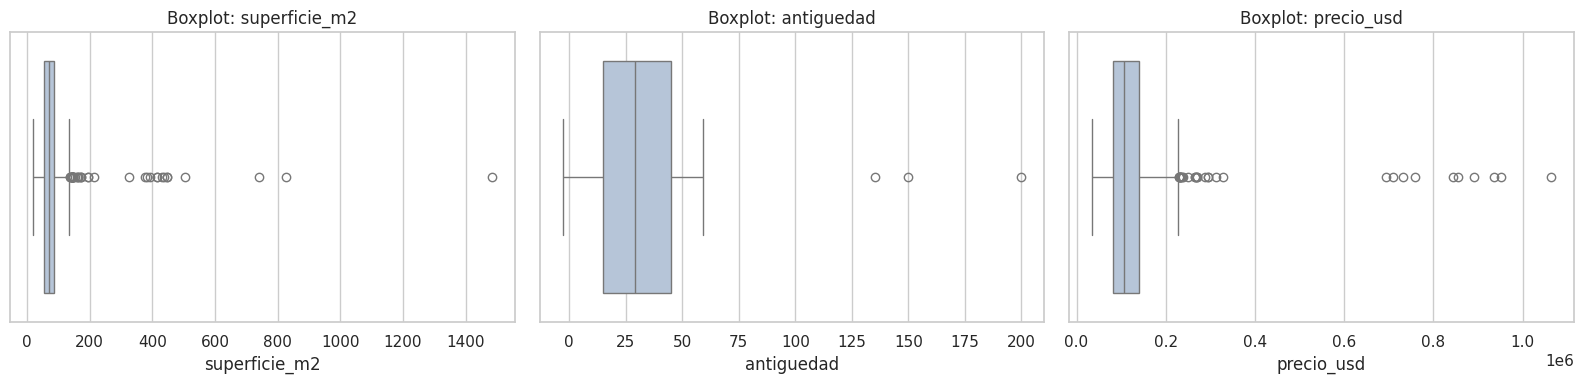

In [ ]:
# Variables numéricas continuas que vamos a analizar una por una
variables = ['superficie_m2', 'antiguedad', 'precio_usd']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, variables):
    sns.boxplot(x=df[col], ax=ax, color='lightsteelblue')   # boxplot horizontal de cada variable
    ax.set_title(f'Boxplot: {col}')
plt.tight_layout(); plt.show()

### 2.2 IQR y Z-Score (métodos estadísticos)

- **IQR:** `IQR = Q3 − Q1`; outlier si cae fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`. Es *robusto*: no depende de la media ni del desvío.
- **Z-Score:** `Z = (x − μ) / σ`; outlier si `|Z| > 3`. Asume distribución normal y **no es robusto**, porque μ y σ se ven afectados por los propios outliers.

In [ ]:
def limites_iqr(serie):
    # Calcula Q1, Q3, IQR y devuelve los límites inferior y superior
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)   # percentiles 25 y 75
    iqr = q3 - q1                                         # rango intercuartílico
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr                 # límite inferior, límite superior

def outliers_iqr(serie):
    # Devuelve una máscara booleana: True si el valor está fuera de los límites IQR
    inf, sup = limites_iqr(serie)
    return (serie < inf) | (serie > sup)

def outliers_z(serie, umbral=3):
    # Devuelve una máscara booleana: True si |Z| > umbral
    z = (serie - serie.mean()) / serie.std(ddof=0)        # Z = (x - media) / desvío (poblacional, igual que scipy)
    return z.abs() > umbral

# Resumen por variable: límites IQR y cantidad de outliers según cada método
filas = []
for col in variables:
    inf, sup = limites_iqr(df[col])
    filas.append({'variable': col,
                  'límite_inf_IQR': round(inf, 1), 'límite_sup_IQR': round(sup, 1),
                  'outliers_IQR': int(outliers_iqr(df[col]).sum()),
                  'outliers_Z(>3)': int(outliers_z(df[col]).sum())})
resumen_uni = pd.DataFrame(filas).set_index('variable')
resumen_uni

,límite_inf_IQR,límite_sup_IQR,outliers_IQR,outliers_Z(>3)
variable,,,,
superficie_m2,5.9,135.5,37,14
antiguedad,-30.0,90.0,3,3
precio_usd,-5214.1,226719.7,30,10


In [ ]:
# Comprobamos que nuestro Z-Score manual coincide con scipy.stats.zscore (debe dar True)
print("Z manual == scipy:", np.allclose((df['precio_usd'] - df['precio_usd'].mean()) / df['precio_usd'].std(ddof=0),
                                       stats.zscore(df['precio_usd'])))

# Máscaras globales: una fila es "outlier univariante" si lo es en AL MENOS UNA variable
mask_iqr_any = np.zeros(len(df), dtype=bool)
mask_z_any = np.zeros(len(df), dtype=bool)
for col in variables:
    mask_iqr_any |= outliers_iqr(df[col]).values          # |= acumula con "o lógico"
    mask_z_any   |= outliers_z(df[col]).values

print("Filas marcadas por IQR en alguna variable:", mask_iqr_any.sum())
print("Filas marcadas por Z-Score en alguna variable:", mask_z_any.sum())

Z manual == scipy: True
Filas marcadas por IQR en alguna variable: 52
Filas marcadas por Z-Score en alguna variable: 17


## 3. Detección bivariante: Scatterplot

Un departamento de 20 m² no es un outlier; un precio de 500.000 USD tampoco. Pero **juntos** sí lo son. El scatterplot permite verlo.

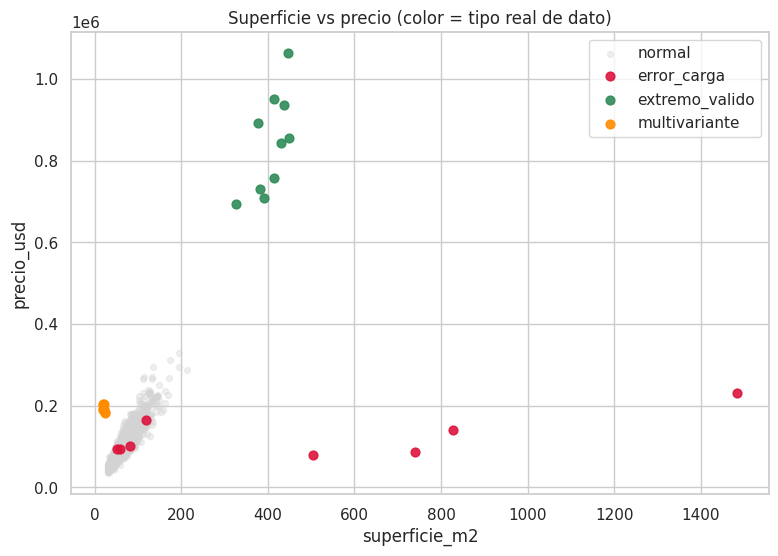

In [ ]:
# Colores por tipo real SOLO para que podamos ver dónde cae cada tipo (en un caso real no tendríamos esta columna)
colores = {'normal': 'lightgray', 'error_carga': 'crimson',
           'extremo_valido': 'seagreen', 'multivariante': 'darkorange'}

fig, ax = plt.subplots(figsize=(9, 6))
for tipo, color in colores.items():
    sub = df[df['tipo_real'] == tipo]
    ax.scatter(sub['superficie_m2'], sub['precio_usd'], c=color, label=tipo,
               alpha=.9 if tipo != 'normal' else .35, s=40 if tipo != 'normal' else 18)
ax.set_xlabel('superficie_m2'); ax.set_ylabel('precio_usd')
ax.set_title('Superficie vs precio (color = tipo real de dato)')
ax.legend(); plt.show()

In [ ]:
# ¿Los outliers multivariantes quedan atrapados por los métodos univariantes?
multi = (df['tipo_real'] == 'multivariante').values
print(f"Multivariantes detectados por IQR univariante: {mask_iqr_any[multi].sum()} de {multi.sum()}")
print(f"Multivariantes detectados por Z-Score univariante: {mask_z_any[multi].sum()} de {multi.sum()}")

# Variable derivada: precio por m². Convierte una relación entre 2 variables en una sola variable
df['precio_m2'] = df['precio_usd'] / df['superficie_m2']
mask_iqr_pm2 = outliers_iqr(df['precio_m2']).values
print(f"\nMultivariantes detectados por IQR sobre precio_m2: {mask_iqr_pm2[multi].sum()} de {multi.sum()}")

Multivariantes detectados por IQR univariante: 0 de 8
Multivariantes detectados por Z-Score univariante: 0 de 8

Multivariantes detectados por IQR sobre precio_m2: 8 de 8


**Lectura:** los 8 departamentos chicos y caros (naranja) se ven claramente fuera de la nube en el scatterplot, pero **ni el IQR ni el Z-Score univariantes detectan ninguno (0 de 8)**: su superficie y su precio, mirados por separado, están dentro de lo esperable. En cambio, al crear la variable derivada `precio_m2` (que resume la relación entre ambas), el IQR los atrapa a los 8. Moraleja: lo multivariante se detecta con scatterplots, variables derivadas o algoritmos multivariantes.

## 4. Detección multivariante: algoritmos no supervisados

### 4.1 Isolation Forest
Construye árboles con cortes aleatorios. Las anomalías, al ser pocas y diferentes, quedan **aisladas con pocos cortes**. El parámetro `contamination` es la proporción esperada de anomalías.

In [ ]:
# Variables de entrada del modelo (todas las numéricas originales)
cols_modelo = ['superficie_m2', 'antiguedad', 'habitaciones', 'precio_usd']

# contamination=0.03: asumimos que ~3 % de los datos son anómalos (en un caso real es un supuesto a justificar)
iso = IsolationForest(n_estimators=200, contamination=0.03, random_state=42)

# fit_predict devuelve -1 para anomalías y 1 para datos normales
pred_iso = iso.fit_predict(df[cols_modelo])
mask_iso = (pred_iso == -1)                       # máscara booleana: True = anomalía

# score_samples: cuanto más negativo, más anómalo (útil para ordenar los casos más sospechosos)
df['score_iso'] = iso.score_samples(df[cols_modelo])

print("Anomalías marcadas por Isolation Forest:", mask_iso.sum())
df.loc[mask_iso].sort_values('score_iso').head(10)[cols_modelo + ['tipo_real', 'score_iso']].round(2)

Anomalías marcadas por Isolation Forest: 30


,superficie_m2,antiguedad,habitaciones,precio_usd,tipo_real,score_iso
975,445.69,3,6,1063562.44,extremo_valido,-0.78
297,437.84,17,6,936562.39,extremo_valido,-0.77
83,448.19,25,6,854910.49,extremo_valido,-0.77
244,430.24,3,6,843179.57,extremo_valido,-0.77
184,414.81,12,6,951395.23,extremo_valido,-0.76
155,378.13,20,6,891145.60,extremo_valido,-0.76
413,413.31,11,6,758046.40,extremo_valido,-0.75
430,381.50,29,6,730602.53,extremo_valido,-0.75
161,391.41,23,6,709064.37,extremo_valido,-0.75
58,325.83,15,6,694475.36,extremo_valido,-0.73


### 4.2 DBSCAN
Algoritmo de clustering por **densidad**: agrupa puntos cercanos (a distancia ≤ `eps`, con al menos `min_samples` vecinos) y marca como **ruido (−1)** los puntos de baja densidad. Como usa distancias, **hay que escalar las variables** antes.

In [ ]:
# DBSCAN usa distancia euclidiana -> estandarizamos para que precio (en miles) no domine sobre antigüedad
cols_db = ['superficie_m2', 'antiguedad', 'precio_usd']
X_db = StandardScaler().fit_transform(df[cols_db])      # media 0, desvío 1 en cada columna

# Probamos distintos eps para ver su sensibilidad: eps chico -> más puntos marcados como ruido
for eps in [0.2, 0.3, 0.4, 0.5, 0.7]:
    etiquetas = DBSCAN(eps=eps, min_samples=8).fit_predict(X_db)
    print(f"eps={eps}: ruido (outliers) = {(etiquetas == -1).sum():4d} | clusters encontrados = {len(set(etiquetas) - {-1})}")

eps=0.2: ruido (outliers) =  154 | clusters encontrados = 3
eps=0.3: ruido (outliers) =   57 | clusters encontrados = 1
eps=0.4: ruido (outliers) =   48 | clusters encontrados = 1
eps=0.5: ruido (outliers) =   29 | clusters encontrados = 1
eps=0.7: ruido (outliers) =   29 | clusters encontrados = 1


In [ ]:
# Elegimos un eps intermedio que no marque demasiados puntos como ruido
EPS = 0.4
db = DBSCAN(eps=EPS, min_samples=8).fit(X_db)
mask_db = (db.labels_ == -1)                            # etiqueta -1 = ruido = outlier
print(f"DBSCAN (eps={EPS}, min_samples=8): {mask_db.sum()} puntos marcados como ruido")

DBSCAN (eps=0.4, min_samples=8): 48 puntos marcados como ruido


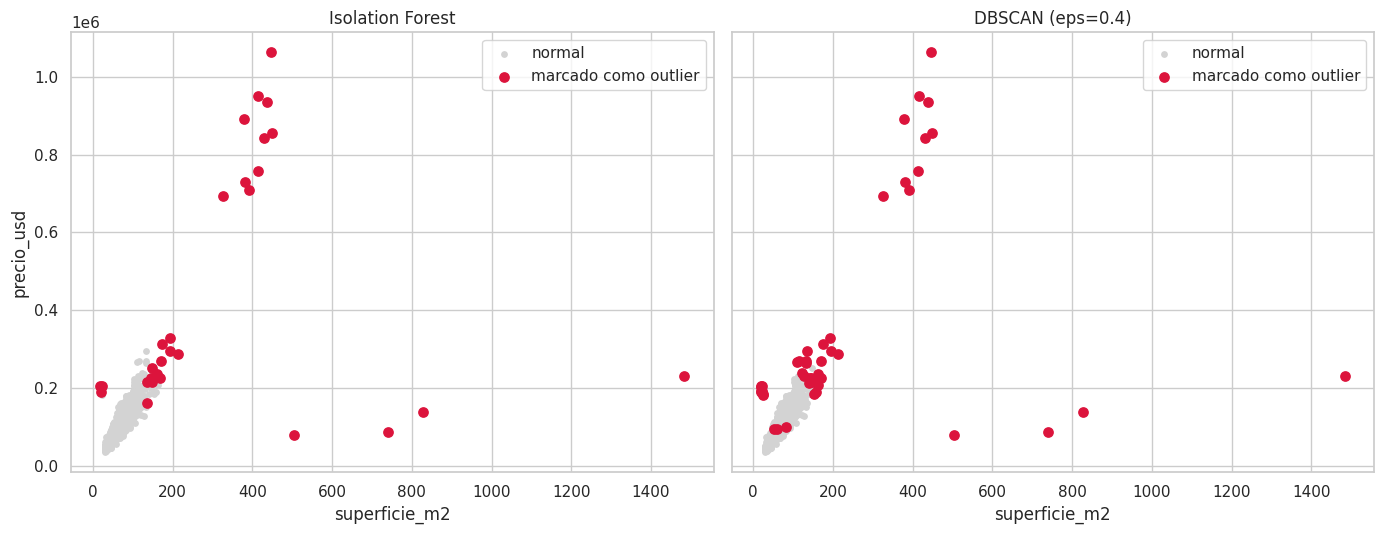

In [ ]:
# Visualizamos qué marcó cada algoritmo sobre el scatter superficie vs precio
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, mask, titulo in zip(axes, [mask_iso, mask_db], ['Isolation Forest', f'DBSCAN (eps={EPS})']):
    ax.scatter(df.loc[~mask, 'superficie_m2'], df.loc[~mask, 'precio_usd'], c='lightgray', s=15, label='normal')
    ax.scatter(df.loc[mask, 'superficie_m2'], df.loc[mask, 'precio_usd'], c='crimson', s=45, label='marcado como outlier')
    ax.set_title(titulo); ax.set_xlabel('superficie_m2'); ax.legend()
axes[0].set_ylabel('precio_usd')
plt.tight_layout(); plt.show()

## 5. Comparación de métodos contra la verdad conocida

In [ ]:
def evaluar(mask, nombre):
    # Para cada método cuenta cuántos de cada tipo real logró marcar
    mask = np.asarray(mask)
    t = df['tipo_real'].values
    return {'método': nombre,
            'total marcados': int(mask.sum()),
            'error_carga (de 8)': int(mask[t == 'error_carga'].sum()),
            'extremo_valido (de 10)': int(mask[t == 'extremo_valido'].sum()),
            'multivariante (de 8)': int(mask[t == 'multivariante'].sum()),
            'normales marcados (falsos +)': int(mask[t == 'normal'].sum())}

comparacion = pd.DataFrame([
    evaluar(outliers_iqr(df['precio_usd']),     'IQR – precio_usd'),
    evaluar(outliers_iqr(df['superficie_m2']),  'IQR – superficie_m2'),
    evaluar(outliers_iqr(df['antiguedad']),     'IQR – antiguedad'),
    evaluar(mask_iqr_any,                       'IQR – cualquier variable'),
    evaluar(mask_z_any,                         'Z-Score – cualquier variable'),
    evaluar(mask_iqr_pm2,                       'IQR – precio_m2 (variable derivada)'),
    evaluar(mask_iso,                           'Isolation Forest'),
    evaluar(mask_db,                            'DBSCAN'),
]).set_index('método')
comparacion

,total marcados,error_carga (de 8),extremo_valido (de 10),multivariante (de 8),normales marcados (falsos +)
método,,,,,
IQR – precio_usd,30,1,10,0,19
IQR – superficie_m2,37,4,10,0,23
IQR – antiguedad,3,3,0,0,0
IQR – cualquier variable,52,7,10,0,35
Z-Score – cualquier variable,17,7,10,0,0
IQR – precio_m2 (variable derivada),23,4,3,8,8
Isolation Forest,30,4,10,4,12
DBSCAN,48,7,10,8,23


**Lectura de la tabla (los números dependen de la semilla y de los parámetros elegidos):**

- **Z-Score:** marcó 17 filas con **0 falsos positivos**, porque con un dato tan asimétrico la media y el desvío se inflan y el umbral queda alto. Pero marcó las 10 mansiones (que son válidas) y no vio ninguna anomalía multivariante.
- **IQR en cualquier variable:** marcó 52 filas, de las cuales **35 son propiedades normales** (falsos positivos). Al ser `precio_usd` y `superficie_m2` asimétricas a la derecha, el IQR sobre variables sesgadas marca como "outliers" valores altos que son parte de la distribución natural.
- **Isolation Forest** (contamination = 3 %): marcó 30 filas, incluyendo las 10 mansiones y solo 4 de las 8 anomalías multivariantes. Sus 10 casos más anómalos son todos mansiones: mide **rareza**, no "error".
- **DBSCAN** (eps = 0,4): marcó 48 filas; atrapó las 8 anomalías multivariantes y 7 de 8 errores, pero con 23 falsos positivos. Es muy sensible a `eps`: pasó de 154 puntos de ruido con eps = 0,2 a 29 con eps = 0,5 o 0,7.
- **Ningún método distingue por sí solo un error de un extremo válido:** todos marcaron las 10 mansiones. Esa decisión requiere criterio de dominio.
- **El valor de antigüedad −3 no lo detecta ningún método estadístico** (el límite inferior IQR es −30); solo una **regla de validez** lo atrapa.

## 6. Tratamiento de outliers

> **Regla de Oro:** nunca eliminar un outlier sin documentar por qué. Si no se puede confirmar que es un error, se mantiene y se usan técnicas robustas.

### 6.1 Eliminación (solo errores confirmados)
Eliminamos únicamente lo que podemos justificar con **reglas de negocio verificables**, no lo que simplemente "parece raro":
- Antigüedad fuera de `[0, 100]` años → imposible físicamente.
- Precio por m² implausible (fuera de 500–6000 USD/m²) → superficie en unidad equivocada, o combinación imposible.

In [ ]:
# Reglas de validez basadas en conocimiento del dominio (no en estadística)
regla_antiguedad = ~df['antiguedad'].between(0, 100)          # True = antigüedad imposible
regla_precio_m2 = ~df['precio_m2'].between(500, 6000)         # True = precio/m² implausible
a_eliminar = regla_antiguedad | regla_precio_m2

print("Filas que incumplen alguna regla:", a_eliminar.sum())
print("\nComposición de lo que se elimina (verificación con la verdad):")
print(df.loc[a_eliminar, 'tipo_real'].value_counts())
print("\nExtremos válidos (mansiones) eliminados:", (df.loc[a_eliminar, 'tipo_real'] == 'extremo_valido').sum())

df_limpio = df.loc[~a_eliminar].copy()                         # dataset sin los errores confirmados
print(f"\nFilas: {len(df)} -> {len(df_limpio)}")

Filas que incumplen alguna regla: 16

Composición de lo que se elimina (verificación con la verdad):
tipo_real
multivariante    8
error_carga      8
Name: count, dtype: int64

Extremos válidos (mansiones) eliminados: 0

Filas: 1000 -> 984


### 6.2 Transformación (logaritmo y raíz cuadrada)
Los extremos válidos (mansiones) **no se eliminan**: se reduce su influencia comprimiendo la escala.

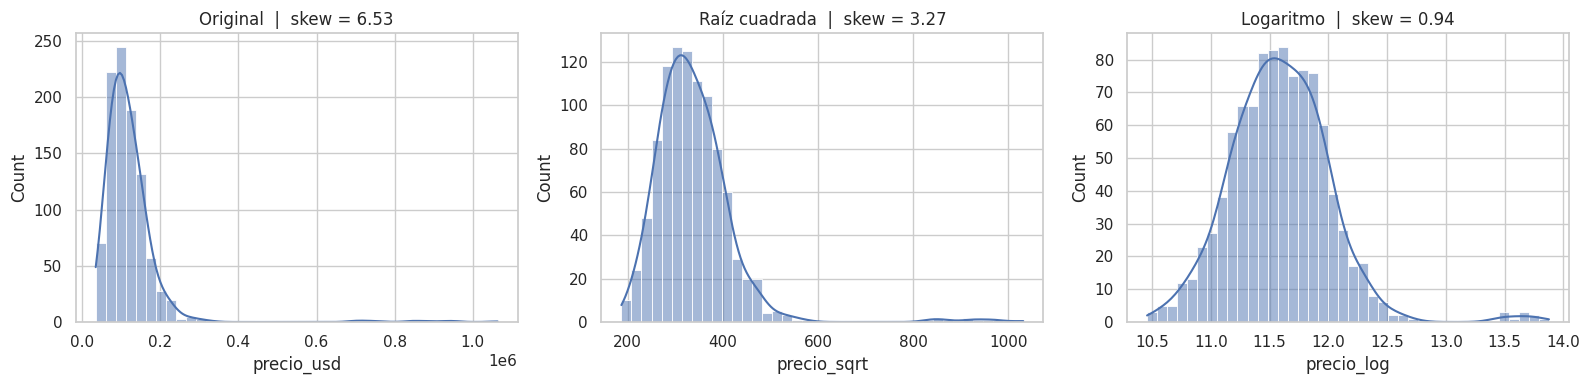

Outliers IQR en precio_usd  : 31
Outliers IQR en precio_sqrt : 20
Outliers IQR en precio_log  : 14


In [ ]:
# Aplicamos las transformaciones al precio del dataset limpio
df_limpio['precio_log'] = np.log1p(df_limpio['precio_usd'])      # log(1 + x): comprime fuerte la cola derecha
df_limpio['precio_sqrt'] = np.sqrt(df_limpio['precio_usd'])      # raíz cuadrada: compresión más suave

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, tit in zip(axes, ['precio_usd', 'precio_sqrt', 'precio_log'],
                        ['Original', 'Raíz cuadrada', 'Logaritmo']):
    sns.histplot(df_limpio[col], kde=True, ax=ax, bins=40)
    ax.set_title(f"{tit}  |  skew = {df_limpio[col].skew():.2f}")
plt.tight_layout(); plt.show()

# Outliers IQR que quedan en cada versión
for col in ['precio_usd', 'precio_sqrt', 'precio_log']:
    print(f"Outliers IQR en {col:12s}: {outliers_iqr(df_limpio[col]).sum()}")

### 6.3 Winsorización (percentiles 1 y 99)
Reemplaza los valores por debajo del percentil 1 o por encima del 99 por el valor de esos percentiles. **No pierde registros** y conserva la distribución central.

In [ ]:
# Percentiles que actuarán como "techo" y "piso"
p1 = df_limpio['precio_usd'].quantile(0.01)
p99 = df_limpio['precio_usd'].quantile(0.99)

# np.clip: todo valor < p1 pasa a valer p1; todo valor > p99 pasa a valer p99
df_limpio['precio_wins'] = np.clip(df_limpio['precio_usd'], p1, p99)

print(f"p1 = {p1:,.0f} | p99 = {p99:,.0f}")
print(f"Registros modificados: {(df_limpio['precio_usd'] != df_limpio['precio_wins']).sum()} | registros perdidos: 0")

# Comparamos el efecto sobre los estadísticos (media, desvío, máximo, asimetría)
pd.DataFrame({
    'Original (con errores)': df['precio_usd'].agg(['mean', 'std', 'max', 'skew']),
    'Tras eliminar errores': df_limpio['precio_usd'].agg(['mean', 'std', 'max', 'skew']),
    'Eliminar + winsorizar': df_limpio['precio_wins'].agg(['mean', 'std', 'max', 'skew']),
}).round(2)

p1 = 43,186 | p99 = 391,103
Registros modificados: 20 | registros perdidos: 0


,Original (con errores),Tras eliminar errores,Eliminar + winsorizar
mean,121599.54,121002.55,116448.92
std,85886.89,86219.85,52033.75
max,1063562.44,1063562.44,391102.58
skew,6.49,6.53,2.04


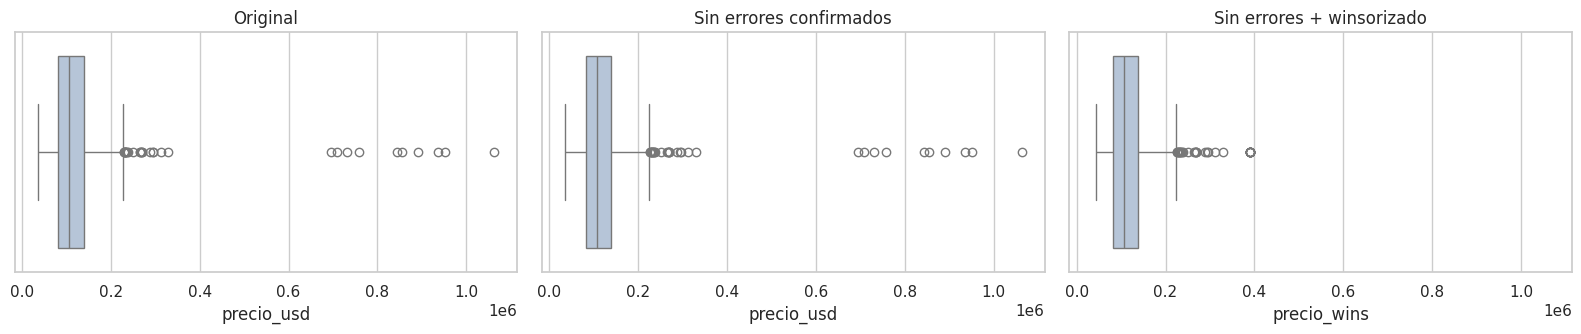

In [ ]:
# Boxplots comparativos de las tres versiones del precio
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5), sharex=True)
for ax, serie, tit in zip(axes, [df['precio_usd'], df_limpio['precio_usd'], df_limpio['precio_wins']],
                          ['Original', 'Sin errores confirmados', 'Sin errores + winsorizado']):
    sns.boxplot(x=serie, ax=ax, color='lightsteelblue'); ax.set_title(tit)
plt.tight_layout(); plt.show()

## 7. Registro de decisiones y conclusiones

In [ ]:
# Registro formal de decisiones (la "Regla de Oro": documentar cada intervención)
decisiones = pd.DataFrame([
    ['Antigüedad fuera de [0, 100] años', 'Eliminación', int(regla_antiguedad.sum()), 'Valor físicamente imposible (error de tipeo)'],
    ['Precio/m² fuera de [500, 6000] USD', 'Eliminación', int((regla_precio_m2 & ~regla_antiguedad).sum()), 'Superficie en pies² o combinación imposible'],
    ['Mansiones (extremos válidos)', 'Conservar + winsorizar / log', int((df['tipo_real'] == 'extremo_valido').sum()), 'Datos reales y coherentes; eliminarlos sesgaría el modelo'],
    ['Cola derecha de precio_usd', 'Transformación log (para modelar)', len(df_limpio), 'Reduce asimetría sin perder registros'],
], columns=['Caso', 'Tratamiento', 'Filas afectadas', 'Justificación'])
decisiones

,Caso,Tratamiento,Filas afectadas,Justificación
0,"Antigüedad fuera de [0, 100] años",Eliminación,4,Valor físicamente imposible (error de tipeo)
1,"Precio/m² fuera de [500, 6000] USD",Eliminación,12,Superficie en pies² o combinación imposible
2,Mansiones (extremos válidos),Conservar + winsorizar / log,10,Datos reales y coherentes; eliminarlos sesgarí...
3,Cola derecha de precio_usd,Transformación log (para modelar),984,Reduce asimetría sin perder registros


## Conclusiones

1. **Métodos usados:** Boxplot (visual), IQR y Z-Score (univariantes), Scatterplot (bivariante), Isolation Forest y DBSCAN (multivariantes) y, como tratamiento, eliminación, transformación (log / raíz) y winsorización.
2. **Cada método ve algo distinto.** Los univariantes detectan bien los errores en una sola variable (antigüedad 150, superficie en pies²) pero son ciegos a combinaciones inusuales; los multivariantes encuentran combinaciones raras pero también marcan los extremos legítimos y dependen de sus parámetros (`contamination`, `eps`).
3. **Eliminar solo lo justificable:** con reglas de dominio (antigüedad fuera de 0–100 años y precio por m² fuera de 500–6000 USD) se eliminaron exactamente 16 filas: los 8 errores de carga y las 8 anomalías multivariantes. **Ninguna mansión fue eliminada.**
4. **Conservar y atenuar lo válido:** las 10 mansiones se mantienen. La transformación logarítmica reduce los outliers IQR de `precio_usd` de 31 a 14 (la raíz cuadrada, a 20), y la winsorización al 1 %–99 % modifica 20 registros sin perder ninguno: el desvío baja de 86.220 a 52.034 y la asimetría de 6,53 a 2,04.
5. **Regla de Oro:** cada intervención quedó registrada en la tabla de decisiones, con su justificación.